# Lump Sum vs Dollar-Cost Averaging vs Cash

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Compares investing a sum all at once, spreading it over twelve months (dollar-cost averaging), and leaving it in cash. One example path shows compounding over time, and a histogram across thousands of simulated markets shows how often each choice wins and by how much.

## When to use

- Investor education on compounding and on the cost of waiting in cash
- Frame the lump-sum vs DCA decision as a distribution of outcomes, not one anecdote
- Show the effect of time in the market on long horizons

## Avoid when

- Showing a single historical or simulated path as proof; one path is an anecdote
- Comparing strategies with different total contributions without saying so

## Alternatives

- Fan chart of each strategy
- Table of win rates and median differences

## Design tips

- Keep the amount invested identical across strategies
- Plot the contributions line so growth is visible as the gap above it
- Report the share of simulations where each strategy wins, and the median margin

## Example

$60,000 available today, 10-year horizon; stocks ~7% ± 15% a year, cash 2% a year; DCA invests $5,000 a month for 12 months (simulated, illustrative; not financial advice).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(31)
amount, months, dca_months = 60_000.0, 120, 12
mu, sigma, cash_rate = 0.07, 0.15, 0.02
n_sims = 5000
r = rng.normal(mu / 12, sigma / np.sqrt(12), (n_sims, months))     # monthly stock returns
cash_m = cash_rate / 12


def simulate(r):
    """Return month-end values for lump sum, DCA and cash, shape (sims, months + 1)."""
    n = r.shape[0]
    lump = amount * np.c_[np.ones(n), np.cumprod(1 + r, axis=1)]
    invested, waiting = np.zeros(n), np.full(n, amount)
    dca = [np.full(n, amount)]
    for t in range(months):
        if t < dca_months:                        # move one tranche into the market
            step = amount / dca_months
            invested, waiting = invested + step, waiting - step
        invested = invested * (1 + r[:, t])
        waiting = waiting * (1 + cash_m)
        dca.append(invested + waiting)
    cash = amount * (1 + cash_m) ** np.arange(months + 1) * np.ones((n, 1))
    return lump, np.array(dca).T, cash


lump, dca, cash = simulate(r)
diff_pct = (lump[:, -1] - dca[:, -1]) / amount * 100
example = int(np.argmin(np.abs(diff_pct - np.median(diff_pct))))   # a typical (median) outcome
path = pd.DataFrame({"Lump sum": lump[example], "DCA over 12 months": dca[example],
                     "Cash at 2%": cash[example]}, index=np.arange(months + 1) / 12)
pd.Series({"lump beats DCA": (diff_pct > 0).mean(), "median gap (% of amount)": np.median(diff_pct)}).round(3)

lump beats DCA              0.583
median gap (% of amount)    2.601
dtype: float64

### Plot

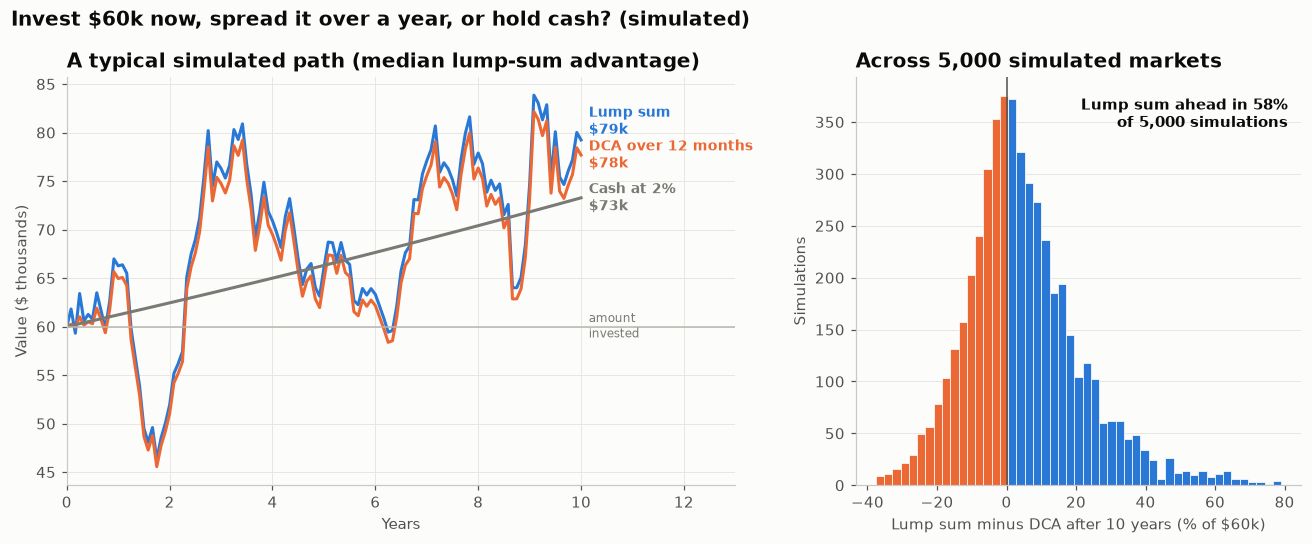

In [3]:
fig, (ax, axh) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.5, 1]})
styles = {"Lump sum": PALETTE[0], "DCA over 12 months": PALETTE[1], "Cash at 2%": "#7a7974"}
ends = path.iloc[-1].sort_values() / 1e3
label_y = ends.to_numpy().copy()
gap = (path.to_numpy().max() - path.to_numpy().min()) / 1e3 * 0.09
for i in range(1, len(label_y)):                 # nudge end labels apart
    label_y[i] = max(label_y[i], label_y[i - 1] + gap)
label_y = dict(zip(ends.index, label_y))
for name, color in styles.items():
    ax.plot(path.index, path[name] / 1e3, color=color, linewidth=2)
    ax.text(path.index[-1] + 0.15, label_y[name], f"{name}\n${path[name].iloc[-1] / 1e3:,.0f}k",
            color=color, va="center", fontsize=9, fontweight="bold")
ax.axhline(amount / 1e3, color="#b8b7b1", linewidth=1)
ax.text(10.15, amount / 1e3, "amount\ninvested", color="#7a7974", fontsize=8, va="center")
ax.set_xlim(0, 13)
ax.set_xlabel("Years")
ax.set_ylabel("Value ($ thousands)")
ax.set_title("A typical simulated path (median lump-sum advantage)")

bins = np.linspace(np.percentile(diff_pct, 0.5), np.percentile(diff_pct, 99.5), 50)
counts, edges = np.histogram(diff_pct, bins)
centers = (edges[:-1] + edges[1:]) / 2
axh.bar(centers, counts, width=np.diff(edges), color=np.where(centers >= 0, PALETTE[0], PALETTE[1]),
        edgecolor="#fcfcfb", linewidth=0.5)
axh.axvline(0, color="#52514e", linewidth=1)
win = (diff_pct > 0).mean()
axh.text(0.97, 0.95, f"Lump sum ahead in {win:.0%}\nof {n_sims:,} simulations", transform=axh.transAxes,
         ha="right", va="top", fontsize=9.5, fontweight="bold")
axh.set_xlabel("Lump sum minus DCA after 10 years (% of $60k)")
axh.set_ylabel("Simulations")
axh.set_title("Across 5,000 simulated markets")
axh.grid(axis="x", visible=False)
fig.suptitle("Invest $60k now, spread it over a year, or hold cash? (simulated)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

On the example path, the lump sum (blue) ends highest, DCA (orange) trails because part of the money waited in cash, and cash (gray) barely grows. The histogram shows the lump sum beat DCA in most simulations, but not all, and DCA's wins came in markets that fell early.

---
Standalone script: [`compounding_dca.py`](compounding_dca.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)